# Understanding Machine Learning Evaluation Metrics

This notebook introduces common evaluation metrics used in machine learning, with simple examples to illustrate each concept.

In [1]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.metrics import ConfusionMatrixDisplay

## 1. Basic Classification Metrics: Precision, Recall, and F1-Score

First, let's establish some key concepts with a simple binary classification scenario.

- **True Positive (TP)**: Model correctly predicts positive class
- **False Positive (FP)**: Model incorrectly predicts positive class (Type I error)
- **True Negative (TN)**: Model correctly predicts negative class
- **False Negative (FN)**: Model incorrectly predicts negative class (Type II error)

In [2]:
# Sample predictions and ground truth
y_true = np.array([1, 0, 1, 1, 0, 1, 0, 0, 1, 1])
y_pred = np.array([1, 0, 0, 1, 0, 1, 1, 0, 1, 0])

# Create and display confusion matrix
cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

print(f"Confusion Matrix:\n{cm}")
print(f"True Positives (TP): {tp}")
print(f"False Positives (FP): {fp}")
print(f"True Negatives (TN): {tn}")
print(f"False Negatives (FN): {fn}")

accuracy = (y_true == y_pred).mean()

print(f"Accuracy: {accuracy}")

Confusion Matrix:
[[3 1]
 [2 4]]
True Positives (TP): 4
False Positives (FP): 1
True Negatives (TN): 3
False Negatives (FN): 2
Accuracy: 0.7


### 1.1 Precision

**Precision** answers: "Of all instances predicted as positive, how many are actually positive?"

$$\text{Precision} = \frac{TP}{TP + FP}$$

- High precision means low false positive rate
- Important when false positives are costly (e.g., spam detection - don't want to mark important emails as spam)

In [3]:
# Calculate precision manually
precision_manual = tp / (tp + fp)
print(f"Precision (manual): {precision_manual:.4f}")

# Using sklearn
precision_sklearn = precision_score(y_true, y_pred)
print(f"Precision (sklearn): {precision_sklearn:.4f}")

Precision (manual): 0.8000
Precision (sklearn): 0.8000


### 1.2 Recall

**Recall** (also called sensitivity or true positive rate) answers: "Of all actual positive instances, how many did we predict correctly?"

$$\text{Recall} = \frac{TP}{TP + FN}$$

- High recall means model captures most positive instances
- Important when false negatives are costly (e.g., disease detection - don't want to miss any positive cases)

In [4]:
# Calculate recall manually
recall_manual = tp / (tp + fn)
print(f"Recall (manual): {recall_manual:.4f}")

# Using sklearn
recall_sklearn = recall_score(y_true, y_pred)
print(f"Recall (sklearn): {recall_sklearn:.4f}")

Recall (manual): 0.6667
Recall (sklearn): 0.6667


### 1.3 F1-Score

**F1-Score** is the harmonic mean of precision and recall, providing a balance between the two metrics.

$$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

- F1-Score is useful when you need to balance precision and recall
- Particularly important for imbalanced datasets where accuracy might be misleading

In [5]:
# Calculate F1-score manually
f1_manual = 2 * (precision_manual * recall_manual) / (precision_manual + recall_manual)
print(f"F1-Score (manual): {f1_manual:.4f}")

# Using sklearn
f1_sklearn = f1_score(y_true, y_pred)
print(f"F1-Score (sklearn): {f1_sklearn:.4f}")

F1-Score (manual): 0.7273
F1-Score (sklearn): 0.7273


### 1.4 Confusion Matrix Visualization

The **confusion matrix** is a table that summarizes the prediction results of a classification model. For binary classification:

- Row 0, Column 0: True Negatives (TN) - Correctly predicted negative class
- Row 0, Column 1: False Positives (FP) - Incorrectly predicted positive class (Type I error)
- Row 1, Column 0: False Negatives (FN) - Incorrectly predicted negative class (Type II error)
- Row 1, Column 1: True Positives (TP) - Correctly predicted positive class

Visualizing the confusion matrix helps in understanding the types of errors your model is making.

<Figure size 800x600 with 0 Axes>

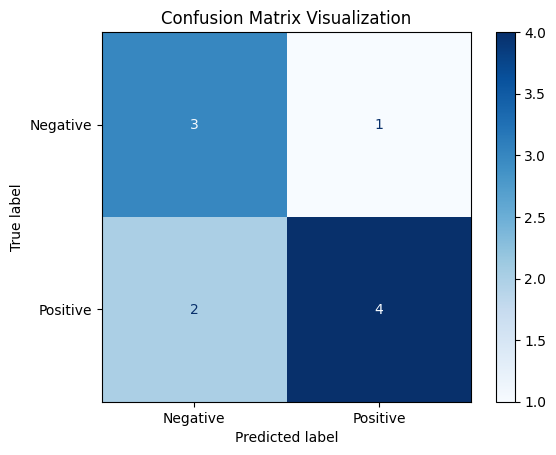

In [6]:
# Visualize confusion matrix
plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative', 'Positive'])
disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title('Confusion Matrix Visualization')
plt.show()

# # Alternative visualization with seaborn
# plt.figure(figsize=(8, 6))
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], 
#             yticklabels=['Negative', 'Positive'])
# plt.xlabel('Predicted')
# plt.ylabel('True')
# plt.title('Confusion Matrix Heatmap')
# plt.show()

## 2. Top-K Accuracy

**Top-K Accuracy** measures the percentage of test samples where the correct label is among the top K predicted labels. This is especially useful for multi-class classification problems.

For example, Top-3 accuracy checks if the correct class is among the model's top 3 predictions.

In [7]:
# Function to calculate Top-K accuracy
def top_k_accuracy(y_true, y_pred_proba, k):
    """Calculate Top-K accuracy
    
    Args:
        y_true: True labels (1D array)
        y_pred_proba: Predicted probabilities for each class (2D array)
        k: Number of top predictions to consider
        
    Returns:
        Top-K accuracy score
    """
    top_k_preds = np.argsort(y_pred_proba, axis=1)[:, -k:]
    matches = [y_true[i] in top_k_preds[i] for i in range(len(y_true))]
    return np.mean(matches)

# Example with multi-class classification
# 5 samples, 4 classes with probabilities
y_true_multi = np.array([0, 2, 1, 3, 0])
y_pred_proba = np.array([
    [0.7, 0.1, 0.1, 0.1],  # Correct class (0) is top prediction
    [0.3, 0.1, 0.5, 0.1],  # Correct class (2) is top prediction
    [0.2, 0.3, 0.4, 0.1],  # Correct class (1) is second best
    [0.1, 0.1, 0.7, 0.1],  # Correct class (3) is not in top 2
    [0.2, 0.3, 0.4, 0.1]   # Correct class (0) is not in top 2
])

# Calculate top-1, top-2, and top-3 accuracy
top_1_acc = top_k_accuracy(y_true_multi, y_pred_proba, 1)
top_2_acc = top_k_accuracy(y_true_multi, y_pred_proba, 2)
top_3_acc = top_k_accuracy(y_true_multi, y_pred_proba, 3)

print(f"Top-1 Accuracy: {top_1_acc:.4f}")
print(f"Top-2 Accuracy: {top_2_acc:.4f}")
print(f"Top-3 Accuracy: {top_3_acc:.4f}")

Top-1 Accuracy: 0.4000
Top-2 Accuracy: 0.8000
Top-3 Accuracy: 1.0000


## 3. Mean Reciprocal Rank (MRR)

**Mean Reciprocal Rank (MRR)** is a statistic used to evaluate systems that return a ranked list of answers. For each query, the reciprocal rank is the inverse of the position of the first correct answer. MRR averages these reciprocal ranks across all queries.

$$\text{MRR} = \frac{1}{|Q|} \sum_{i=1}^{|Q|} \frac{1}{\text{rank}_i}$$

Where $|Q|$ is the number of queries and $\text{rank}_i$ is the position of the first correct answer for the $i$-th query.

- If the correct answer is at position 1, its reciprocal rank is 1
- If the correct answer is at position 2, its reciprocal rank is 1/2
- If the correct answer is at position 3, its reciprocal rank is 1/3
- And so on...

MRR is especially useful in search, question answering, and recommendation systems.

In [8]:
# Function to calculate MRR
def mean_reciprocal_rank(y_true, y_pred_ranks):
    """Calculate Mean Reciprocal Rank
    
    Args:
        y_true: True labels (1D array)
        y_pred_ranks: Predicted rankings for each sample (2D array)
        
    Returns:
        MRR score
    """
    reciprocal_ranks = []
    
    for i, true_class in enumerate(y_true):
        # Find position of true class (0-indexed, so add 1 for rank)
        ranks = np.argsort(y_pred_ranks[i])[::-1]  # Sort in descending order
        rank = np.where(ranks == true_class)[0][0] + 1
        reciprocal_ranks.append(1.0 / rank)
        
    return np.mean(reciprocal_ranks)

# Example scenarios for MRR
true_answers = np.array([2, 0, 1, 3])

# Model rankings for each query (highest score = highest rank)
predicted_scores = np.array([
    [0.2, 0.1, 0.5, 0.2],  # True answer (2) is ranked 1st
    [0.6, 0.1, 0.2, 0.1],  # True answer (0) is ranked 1st
    [0.2, 0.3, 0.4, 0.1],  # True answer (1) is ranked 2nd
    [0.5, 0.2, 0.2, 0.1]   # True answer (3) is ranked 4th
])

mrr = mean_reciprocal_rank(true_answers, predicted_scores)
print(f"Mean Reciprocal Rank (MRR): {mrr:.4f}")

# Let's break it down
print("\nBreakdown:")
for i, true_class in enumerate(true_answers):
    ranks = np.argsort(predicted_scores[i])[::-1]
    rank = np.where(ranks == true_class)[0][0] + 1
    print(f"Query {i+1}: True answer rank = {rank}, Reciprocal Rank = {1.0/rank:.4f}")

Mean Reciprocal Rank (MRR): 0.6875

Breakdown:
Query 1: True answer rank = 1, Reciprocal Rank = 1.0000
Query 2: True answer rank = 1, Reciprocal Rank = 1.0000
Query 3: True answer rank = 2, Reciprocal Rank = 0.5000
Query 4: True answer rank = 4, Reciprocal Rank = 0.2500


## 4. F-Beta Score

The **F-beta score** generalises the F1-score by introducing a parameter $\beta$ that controls how much weight recall receives relative to precision:

$$F_\beta = (1 + \beta^{2})\;\frac{\text{Precision} \times \text{Recall}}{\beta^{2}\;\text{Precision} + \text{Recall}}$$

| $\beta$ value | Emphasis | Use-case example |
|---|---|---|
| $\beta = 0.5$ | **Precision** matters more | Spam detection — marking a legitimate email as spam is costly |
| $\beta = 1.0$ | Equal weight (standard F1) | General-purpose balanced metric |
| $\beta = 2.0$ | **Recall** matters more | Cancer screening — missing a true positive could be fatal |

$\beta$ can be interpreted as *"how many times more important recall is than precision."*  Because the formula uses $\beta^{2}$, setting $\beta = 2$ makes recall **four times** as influential as precision, and $\beta = 0.5$ makes precision **four times** as influential as recall.

In [ ]:
from sklearn.metrics import fbeta_score

def f_beta(precision, recall, beta):
    """Compute the F-beta score from precision and recall."""
    beta_sq = beta ** 2
    return (1 + beta_sq) * precision * recall / (beta_sq * precision + recall)

f_05_manual = f_beta(precision_manual, recall_manual, beta=0.5)
f1_manual_  = f_beta(precision_manual, recall_manual, beta=1.0)
f2_manual   = f_beta(precision_manual, recall_manual, beta=2.0)

print("Manual computation (from TP=4, FP=1, FN=2):")
print(f"  F0.5 (precision-weighted) : {f_05_manual:.4f}")
print(f"  F1   (balanced)           : {f1_manual_:.4f}")
print(f"  F2   (recall-weighted)    : {f2_manual:.4f}")

# --- sklearn verification ---
f_05_sk = fbeta_score(y_true, y_pred, beta=0.5)
f1_sk   = fbeta_score(y_true, y_pred, beta=1.0)
f2_sk   = fbeta_score(y_true, y_pred, beta=2.0)

print("\nsklearn verification:")
print(f"  F0.5 : {f_05_sk:.4f}")
print(f"  F1   : {f1_sk:.4f}")
print(f"  F2   : {f2_sk:.4f}")

Manual computation (from TP=4, FP=1, FN=2):
  F0.5 (precision-weighted) : 0.7692
  F1   (balanced)           : 0.7273
  F2   (recall-weighted)    : 0.6897

sklearn verification:
  F0.5 : 0.7692
  F1   : 0.7273
  F2   : 0.6897


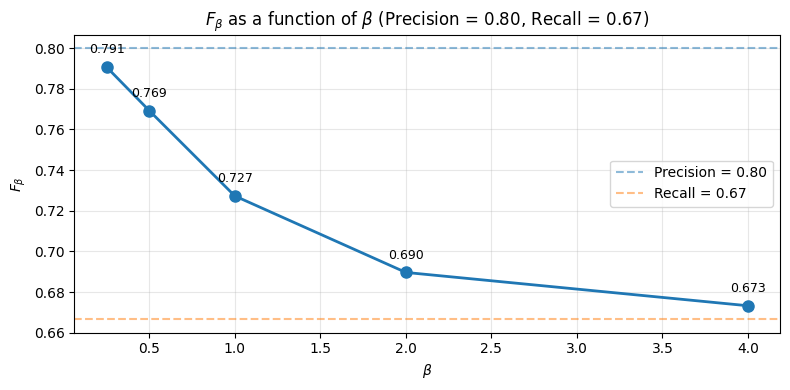

In [10]:
betas = [0.25, 0.5, 1.0, 2.0, 4.0]
scores = [f_beta(precision_manual, recall_manual, b) for b in betas]

plt.figure(figsize=(8, 4))
plt.plot(betas, scores, "o-", linewidth=2, markersize=8)
plt.axhline(y=precision_manual, color="tab:blue", linestyle="--", alpha=0.5, label=f"Precision = {precision_manual:.2f}")
plt.axhline(y=recall_manual, color="tab:orange", linestyle="--", alpha=0.5, label=f"Recall = {recall_manual:.2f}")
for b, s in zip(betas, scores):
    plt.annotate(f"{s:.3f}", (b, s), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9)
plt.xlabel(r"$\beta$")
plt.ylabel(r"$F_\beta$")
plt.title(r"$F_\beta$ as a function of $\beta$ (Precision = 0.80, Recall = 0.67)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Intuitive interpretation for our sample confusion matrix

| Metric | Value | What it tells us |
|---|---|---|
| **F0.5 = 0.7692** | Closer to Precision (0.80) | Because β < 1 de-emphasises recall, the score is pulled toward precision. A system optimised for F0.5 would tolerate missing a few true positives (lower recall) as long as the positives it *does* flag are almost always correct. **Think spam filter**: a false positive (blocking a real email) is worse than a false negative (letting spam through). |
| **F1 = 0.7273** | Harmonic mean of both | The standard balanced trade-off. |
| **F2 = 0.6897** | Closer to Recall (0.67) | Because β > 1 amplifies recall's influence, the score is pulled toward recall. A system optimised for F2 would accept more false positives to avoid missing true positives. **Think cancer screening**: a false negative (missed tumour) is far more dangerous than a false positive (an extra biopsy). |

**Key take-away:** As β increases the F-beta score *decreases* here because our recall (0.67) is the weaker metric.  Raising β shines a harsher spotlight on that weakness.